# Lab 05: How to manage what an agent sees

## Goal

Measure what the model reads on every call, and cut it with Agent Skills, prompt caching and compaction. The moment
that teaches it: the same refund question costs 2,391 input tokens on its first call when every shop policy
and playbook rides in the system prompt, and 515 with a short list of skills that the agent loads only
when a question needs one. That list works only when each description says when to use its skill: with vague
descriptions, the agent loaded skills for a question none of them covers in 5 of 5 runs, and paid for
every load.

## What you will learn

- How to list what fills the context on one call (system prompt, tool schemas, history, tool results) and count each
  part from `usage`.
- How to write an Agent Skill: a folder with a `SKILL.md` whose frontmatter holds `name` and `description`, a body
  of steps, and a reference file.
- How to load skills in three levels: the list from the frontmatter, the body on request, the reference only when
  the body points to it.
- How to compare a prompt that carries everything with one that loads on demand, on the first call and over the
  whole question.
- How to read `cached_tokens` and `cache_write_tokens` in `usage` and price a call with them.
- How to compact a long conversation in your own code, count what it saves and what the summary call costs, and
  check that a detail survived; and which APIs and frameworks compact for you.

**Coming from:** lab 03 wrote the agent loop and measured it: every call sends the whole message list again, so the
input tokens grow with each turn. This lab looks inside that list, part by part, and cuts it.

## The support desk and its rules

The agent in this lab helps a support representative at Chinook, an online music shop. The shop's rules are the 20
policy files in `data/corpus/` (refunds, damaged media, accounts, shipping, support hours and more). Its customers,
invoices and reps are in `data/chinook.db`. Most questions in this lab are about ticket 14 in the same folder:

> Two invoices, same album, same day, 9.99 each. Refunds policy: refund the later invoice in full.

Every rule the agent needs has to reach the model through the request: the model has no copy of the shop's
policies. The question this lab answers is **which of them to send, and when**.

## Setup

The config cell is the same in every lab (lab 00 explains it line by line). It finds the repository folder by
`models.env`, reads the model name and prices from it, and finds your key in `.env` without printing it. This lab
adds `json` (tool arguments), `sqlite3` (the database), `yaml` (to read a skill's frontmatter) and `OpenAI` with
`omit` (Part A says what `omit` is for).

In [1]:
from pathlib import Path
import json
import os
import sqlite3

import yaml
from dotenv import dotenv_values
from openai import OpenAI, omit

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The client, the database (opened read-only: `mode=ro` makes SQLite refuse every write) and the four prices this lab
uses, in US dollars per million tokens. Part E explains the two cache prices.

In [2]:
client = OpenAI()
db = sqlite3.connect(f"file:{ROOT / 'data' / 'chinook.db'}?mode=ro", uri=True, check_same_thread=False)
LAB = ROOT / "05_Context_And_Skills"

PRICE_INPUT = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_CACHED = float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
PRICE_CACHE_WRITE = float(settings["PRICE_CACHE_WRITE_PER_MILLION"])
PRICE_OUTPUT = float(settings["PRICE_OUTPUT_PER_MILLION"])
print("input", PRICE_INPUT, "| cached input", PRICE_CACHED, "| cache write", PRICE_CACHE_WRITE, "| output", PRICE_OUTPUT)

input 0.1 | cached input 0.01 | cache write 0.125 | output 0.5


## Part A: Count what the model reads on one call

The model keeps nothing between calls. Each request carries everything it will read: the system prompt, the
schema of every tool, the conversation so far and every tool result in it. We pay for all of it, on every call. So
before cutting anything, we list the parts of one real call and count each one.

**The desk's instructions.** A short system prompt for the agent, and the question we will send.

In [3]:
BASE = (
    "You are the support desk assistant for Chinook, an online music shop. You help a support representative "
    "answer customers. Answer in two to four sentences. Use only the shop's rules you are given; if they do not "
    "cover the question, say so."
)
HELENA = "How many invoices does Helena Holý have, and what has she spent in total?"
print(len(BASE), "characters in the system prompt")

238 characters in the system prompt


**The desk's one tool.** `get_invoices` reads a customer's invoices from the database. The query joins each customer
row to its invoice rows, matches the full name (`FirstName || ' ' || LastName` joins the two with a space), and the
`?` placeholder takes the name from the tuple `(customer_name,)`, so a name is never pasted into the SQL text. The
function returns plain text: that text is what the model will read. We call it ourselves first.

In [4]:
def get_invoices(customer_name):
    # One line per invoice (number, date, total), then the count and the sum
    rows = db.execute(
        "SELECT i.InvoiceId, substr(i.InvoiceDate, 1, 10), i.Total FROM invoices i "
        "JOIN customers c ON c.CustomerId = i.CustomerId "
        "WHERE c.FirstName || ' ' || c.LastName = ? ORDER BY i.InvoiceDate",
        (customer_name,),
    ).fetchall()
    if not rows:
        return "no customer with that exact name"
    lines = [f"invoice {number}, {date}, {total:.2f}" for number, date, total in rows]
    lines.append(f"{len(rows)} invoices, total {sum(total for _, _, total in rows):.2f}")
    return "\n".join(lines)


print(get_invoices("Helena Holý"))

invoice 46, 2009-07-11, 8.91
invoice 175, 2011-02-15, 1.98
invoice 198, 2011-05-20, 3.96
invoice 220, 2011-08-22, 5.94
invoice 272, 2012-04-11, 0.99
invoice 393, 2013-10-03, 1.98
invoice 404, 2013-11-13, 25.86
7 invoices, total 49.62


Seven invoices and a total of 49.62: the answer the agent should give. The model never sees this function, only its
**schema**: a name, a description and the shape of the arguments, as JSON. `"strict": True` makes the API hold the
model's arguments to that shape (lab 02 explains the schema field by field). This dictionary is sent with every call
that offers the tool, whether the model uses it or not.

In [5]:
INVOICES_TOOL = {
    "type": "function",
    "function": {
        "name": "get_invoices",
        "description": "List a customer's invoices (number, date, total) from the shop's database, by full name.",
        "parameters": {
            "type": "object",
            "properties": {"customer_name": {"type": "string", "description": "First and last name, e.g. Helena Holý"}},
            "required": ["customer_name"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}
print(len(json.dumps(INVOICES_TOOL)), "characters of JSON")

391 characters of JSON


**One real call, and its `usage`.** We send the system prompt, the question and the tool, and print the reply's
`usage`: the API's own count of what we sent and what came back. Two settings appear in every call of this lab:

- `max_completion_tokens=300` caps the reply. A tool call or a short answer needs far less.
- `reasoning_effort=EFFORT or omit`. `omit` tells the SDK to leave a parameter out of the request. When
  `REASONING_EFFORT` in `models.env` is empty (a model without reasoning), `EFFORT` is `None`, and sending
  `reasoning_effort=None` returns an error; `EFFORT or omit` sends nothing in that case.

In [6]:
messages = [{"role": "system", "content": BASE}, {"role": "user", "content": HELENA}]
response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=[INVOICES_TOOL],
    max_completion_tokens=300,
    reasoning_effort=EFFORT or omit,
)
print(response.usage)
print(response.choices[0].message.tool_calls)

CompletionUsage(completion_tokens=22, prompt_tokens=225, total_tokens=247, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=0, audio_tokens=0, reasoning_tokens=0, rejected_prediction_tokens=0, text_tokens=None), prompt_tokens_details=PromptTokensDetails(audio_tokens=0, cache_write_tokens=0, cached_tokens=0, image_tokens=None, text_tokens=None))
[ChatCompletionMessageFunctionToolCall(id='call_QEkIszi6cYdAE0u56LEvnaU5', function=Function(arguments='{"customer_name":"Helena Holý"}', name='get_invoices'), type='function')]


Three numbers to read in `usage`:

- `prompt_tokens`: everything we sent, counted in **tokens** (pieces of words; English text runs at about four
  characters per token). This is the number this lab tries to shrink.
- `completion_tokens`: what the model wrote back, here one tool call.
- `prompt_tokens_details`: a breakdown of the input. `cached_tokens` and `cache_write_tokens` are both 0 here; Part E
  comes back to them.

`prompt_tokens` is one total. To see what each part costs, we send the same request with one part at a time added
and read the difference. The helper below sends a request and returns only `prompt_tokens`, the same call as above.
`tools=tools or omit` leaves the tools out of the request when we pass none.

In [7]:
def prompt_tokens(messages, tools=None):
    # Send one request and return the API's count of its input tokens
    response = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        tools=tools or omit,
        max_completion_tokens=300,
        reasoning_effort=EFFORT or omit,
    )
    return response.usage.prompt_tokens


question_only = prompt_tokens([{"role": "user", "content": HELENA}])
with_system = prompt_tokens(messages)
with_tool = prompt_tokens(messages, [INVOICES_TOOL])
print("the question alone:  ", question_only)
print("+ the system prompt: ", with_system, f"(+{with_system - question_only})")
print("+ the tool schema:   ", with_tool, f"(+{with_tool - with_system})")

the question alone:   23
+ the system prompt:  78 (+55)
+ the tool schema:    225 (+147)


Read it from the top:

- **The question alone** costs 23 tokens: its words plus a few tokens of formatting the API adds around
  every message.
- **The system prompt** adds 55 tokens for 238 characters.
- **The tool schema** adds 147 tokens. The model reads every tool's schema on every call, even a call that
  uses no tool. Ten tools of this size cost about ten times this, before anyone asks a question.

Those three parts are the first call. On the second call, the list also holds the model's tool call and the tool's
result. We run the tool call from the response above, append both messages and count again.

In [8]:
call = response.choices[0].message.tool_calls[0]
result = get_invoices(**json.loads(call.function.arguments))

# The model's message (turned into a plain dict like the others) and the tool's result join the list
messages.append(response.choices[0].message.model_dump(exclude_none=True))
messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

second_call = prompt_tokens(messages, [INVOICES_TOOL])
print("second call:", second_call, f"(+{second_call - with_tool} for the tool call and its result)")

second call: 386 (+161 for the tool call and its result)


The second call sends 386 tokens: the first call's 225 again, plus 161 for the model's tool
call and the eight lines of invoices. `model_dump(exclude_none=True)` turned the SDK's message object into a plain
dictionary, so the list holds one kind of item.

So the context of one call has four parts, and each is paid again on every later call:

| Part | Where it comes from | Grows when |
|---|---|---|
| System prompt | our code, once per conversation | we put more rules in it |
| Tool schemas | our code, every call | we add tools |
| History | every user message and model reply so far | the conversation goes on |
| Tool results | what our tools returned | a tool returns a lot of text |

The rest of the lab works on the two we control most: what the system prompt carries (Parts B to E) and how long
the history gets (Part F).

**Checkpoint A.** You should see the question alone at about 23 tokens, the system prompt adding about
55 and the tool schema about 147, and the second call larger than the first by the tool call and its
result (ours: +161). Why does the tool schema cost tokens on a call where the model writes a plain answer?

## Part B: Write the refund steps as an Agent Skill

The desk needs steps for whole kinds of request: how to handle a refund, a damaged record, an account change. If
we put all of them in the system prompt, every call pays for all of them, including the call about Helena's
invoices. An **Agent Skill** packages one kind of request so that it can load only when needed. It is an open format
([agentskills.io](https://agentskills.io/specification)), first developed by Anthropic; Claude Code, OpenAI's Codex
and the OpenAI API's [skills support](https://developers.openai.com/api/docs/guides/tools-skills) read the same
folders, among other agent products. A skill is:

- a **folder** named after the skill;
- a `SKILL.md` file inside it that opens with **frontmatter** (a few lines of YAML between two `---` lines) holding
  `name` and `description`, followed by a **body** of instructions in markdown;
- optional `references/`, `scripts/` and `assets/` folders for material the body points to.

We wrote three skills for this lab from the shop's policies. Here is the folder:

In [9]:
SKILLS = LAB / "skills"
for path in sorted(SKILLS.rglob("*")):
    if path.is_file():
        print(path.relative_to(SKILLS))

account-changes/SKILL.md
damaged-media/SKILL.md
refund-requests/SKILL.md
refund-requests/references/duplicate-charges.md


Three skill folders, one `SKILL.md` each, and one reference file inside `refund-requests`. Here is the whole
`SKILL.md` of the refund skill, as the file stores it:

In [10]:
text = (SKILLS / "refund-requests" / "SKILL.md").read_text()
print(text)

---
name: refund-requests
description: Decide whether a Chinook order is refunded, which invoice and how much, and how long the money takes to arrive. Use when a customer asks for their money back, was charged twice, wants a partial refund for defective tracks, or regrets a digital purchase.
---

# Refund requests

Follow these steps for any request to give money back.

1. **Find the invoice.** Ask for the invoice number if the customer did not give it. Never guess one.
2. **Check the reason against the rules:**
   - A customer who changed their mind about a digital purchase gets no refund.
   - When only some tracks on a multi-disc set are defective, refund those tracks only (a partial refund).
   - A disc or record that arrived damaged is replaced first, not refunded: use the `damaged-media` skill.
   - **Charged twice:** read `references/duplicate-charges.md` before you answer. It says which invoice to refund.
3. **Say where the money goes and when.** Refunds go back to the original

The file has two parts:

- **Frontmatter**, between the `---` lines. `name` must match the folder name (lowercase letters, digits and
  hyphens). `description` says **what the skill does and when to use it**: it is the only part the model reads
  before deciding to load the skill.
- **The body**, everything after the second `---`: the steps, written for the model. Step 2 points to a file in
  `references/` for one case, charged twice; the body does not repeat what that file says.

**Reading the frontmatter in Python.** `text.split("---", 2)` cuts the text at the first two `---` lines only (the 2
is the maximum number of cuts), so a `---` later in the body stays where it is. The three pieces are the empty text
before the first `---`, the frontmatter and the body. `yaml.safe_load` turns the frontmatter into a dictionary.

In [11]:
before, front, body = text.split("---", 2)
meta = yaml.safe_load(front)
print(repr(before))
print(meta)
print(len(body.strip()), "characters of body")

''
{'name': 'refund-requests', 'description': 'Decide whether a Chinook order is refunded, which invoice and how much, and how long the money takes to arrive. Use when a customer asks for their money back, was charged twice, wants a partial refund for defective tracks, or regrets a digital purchase.'}
965 characters of body


`before` is empty, and `meta` is a plain dictionary with two keys, `name` and `description`, read from the YAML.
The body is 965 characters of steps.

We do the same for all three skills. `read_skill` returns the frontmatter dictionary, the body and the folder, and
the loop keeps them in a dictionary keyed by the skill's name, the name the model will use to ask for a skill. The
check under it tests the rules the format sets for the frontmatter.

In [12]:
import re


def read_skill(folder):
    # The frontmatter as a dict, the body as text, and the folder the skill lives in
    _, front, body = (folder / "SKILL.md").read_text().split("---", 2)
    return yaml.safe_load(front), body.strip(), folder


SKILL_SET = {}
for folder in sorted(SKILLS.iterdir()):
    if (folder / "SKILL.md").exists():
        meta, body, folder = read_skill(folder)
        SKILL_SET[meta["name"]] = (meta, body, folder)

for name, (meta, body, folder) in SKILL_SET.items():
    ok = (name == folder.name and re.fullmatch(r"[a-z0-9]+(-[a-z0-9]+)*", name)
          and 0 < len(meta["description"]) <= 1024 and body)
    print("✅" if ok else "❌", name, "|", len(meta["description"]), "characters of description |", len(body), "of body")

✅ account-changes | 221 characters of description | 670 of body
✅ damaged-media | 222 characters of description | 699 of body
✅ refund-requests | 253 characters of description | 965 of body


Three skills, each with a name that matches its folder, a description under the 1,024-character limit and a body.
`re.fullmatch` checks the whole name against the pattern: lowercase letters and digits, with single hyphens between
words.

A pass establishes that each file follows the format, so any agent product that reads Agent Skills can load them. It does
not establish that a description is **good**, that the model will pick the right skill from it. Part C tests that
on real questions.

**Checkpoint B.** `meta` prints as a dictionary with `name: 'refund-requests'` and its description, and the check
prints three ✅ lines. What would break if the folder were renamed `refunds` and the frontmatter left as it is?

## Part C: Load skills in three levels, only when they apply

Now the agent gets the skills, in the three levels the format defines:

1. **The list** (level 1): every skill's `name` and `description`, in the system prompt from the start. A few dozen
   tokens per skill.
2. **The body** (level 2): `SKILL.md` without its frontmatter, sent only when the model asks for the skill with a
   `load_skill` tool.
3. **A reference** (level 3): a file inside the skill's folder, sent only when the body points to it and the model
   asks for it with `read_skill_file`.

In the picture, what stays in every call is white, what our code sends on request is lime, and the model, which
decides what to ask for, is dark.

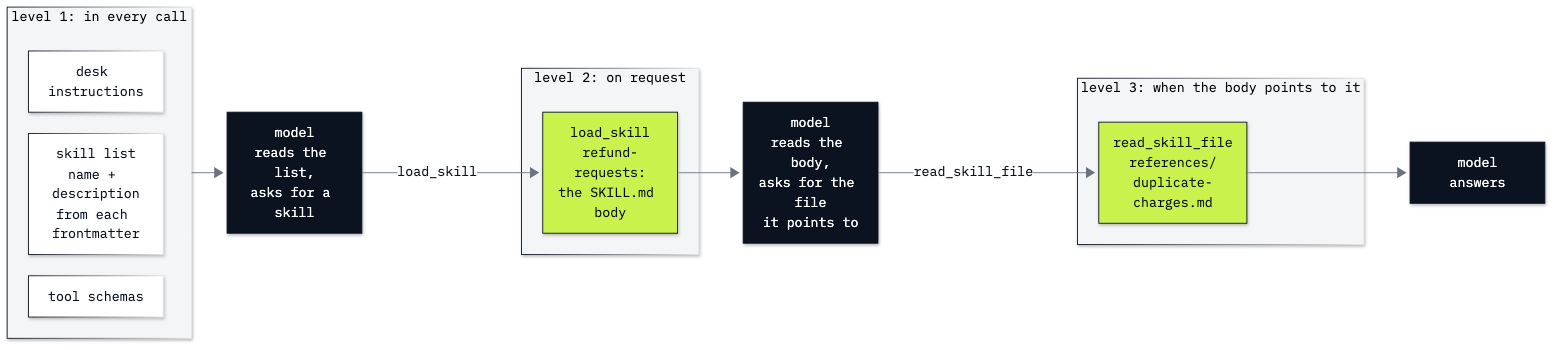

In [13]:
from IPython.display import Image

Image("resources/lab05_three_levels.png", width=760)

**Level 1: the list, built from the frontmatter.** One line per skill. Because the list is built from the
frontmatter, it cannot drift from the skills: change a description in its `SKILL.md`, and the list changes with it.

In [14]:
def skill_list(skills):
    # Level 1: one line per skill, its name and its description
    return "\n".join(f"- {name}: {meta['description']}" for name, (meta, body, folder) in skills.items())


print(skill_list(SKILL_SET))

- account-changes: Change the email on a customer's account or delete the account, within the once-a-year email rule, and say what deletion keeps. Use when a customer asks to update their email or login, or to close or delete their account.
- damaged-media: Handle a CD or vinyl record that arrived cracked, warped or will not play, with a free replacement, the photo we need, and when to refund instead. Use when a customer reports physical damage to a disc, record or boxed set.
- refund-requests: Decide whether a Chinook order is refunded, which invoice and how much, and how long the money takes to arrive. Use when a customer asks for their money back, was charged twice, wants a partial refund for defective tracks, or regrets a digital purchase.


The system prompt with skills, which we call the **thin** prompt: the desk's instructions, one sentence on how to
use the skills, and the list. The sentence asks the model to check the skills before every answer and load one if
it **might** apply, a common instruction in agents that use skills (a skill loaded once too often is cheaper than a
rule missed).

In [15]:
HOW_TO_USE = (
    "Skills: each skill below holds the steps for one kind of request. Check the skills before you answer: "
    "if one might apply, load it with load_skill."
)
THIN_SYSTEM = BASE + "\n\n" + HOW_TO_USE + "\n\n" + skill_list(SKILL_SET)

base_only = prompt_tokens([{"role": "system", "content": BASE}, {"role": "user", "content": HELENA}])
with_list = prompt_tokens([{"role": "system", "content": THIN_SYSTEM}, {"role": "user", "content": HELENA}])
print("the skill list and its instruction add", with_list - base_only, "tokens")

the skill list and its instruction add 192 tokens


192 tokens for three skills. An agent with fifty skills pays about seventeen times that on every call,
far less than fifty bodies.

**Level 2: the body on request.** `load_skill` returns a skill's body, and below it the names of the other files in
its folder, without their content: the model learns that `references/duplicate-charges.md` exists, and reads it only
if it needs it. `rglob("*")` walks every file under the folder; `relative_to(folder)` prints each path from the
skill's folder down. We call it ourselves first.

In [16]:
def load_skill(name):
    # Level 2: the body of SKILL.md, then the names (not the content) of the skill's other files
    meta, body, folder = SKILL_SET[name]
    files = sorted(str(p.relative_to(folder)) for p in folder.rglob("*") if p.is_file() and p.name != "SKILL.md")
    if files:
        body += "\n\nFiles in this skill: " + ", ".join(files)
    return body


print(load_skill("refund-requests"))

# Refund requests

Follow these steps for any request to give money back.

1. **Find the invoice.** Ask for the invoice number if the customer did not give it. Never guess one.
2. **Check the reason against the rules:**
   - A customer who changed their mind about a digital purchase gets no refund.
   - When only some tracks on a multi-disc set are defective, refund those tracks only (a partial refund).
   - A disc or record that arrived damaged is replaced first, not refunded: use the `damaged-media` skill.
   - **Charged twice:** read `references/duplicate-charges.md` before you answer. It says which invoice to refund.
3. **Say where the money goes and when.** Refunds go back to the original payment method, 5 to 10 business days
   after support approves the request.
4. **Escalate** a refund over 100 dollars to the support manager instead of approving it.

Your reply names the invoice number, the amount refunded, where it goes and how long it takes.

Files in this skill: references/d

The body, then the last line names the reference file. **Level 3: a file inside the skill.** `read_skill_file`
takes the skill's name and a path inside its folder.

⚠️ The path comes from the model, so the function must not read anything outside the skill's folder: a path such
as `../../../.env` would otherwise reach your key. `resolve()` turns the path into a full one with every `..`
worked out, and the function refuses any path whose parents do not include the skill's folder.

In [17]:
def read_skill_file(skill, path):
    # Level 3: one file inside the skill's folder, and nothing outside it
    folder = SKILL_SET[skill][2].resolve()
    target = (folder / path).resolve()
    if folder not in target.parents or not target.is_file():
        return "no such file in this skill"
    return target.read_text()


print(read_skill_file("refund-requests", "references/duplicate-charges.md"))
print(read_skill_file("refund-requests", "../../../.env"))

# Duplicate charges

A duplicate charge is **two invoices for the same album, for the same customer, on the same day**. Two invoices on
different days, or for different albums, are two purchases: ask the customer which one they mean.

What to do:

1. Read both invoice numbers and both amounts. If the amounts differ, it is not a duplicate: escalate.
2. Refund the **later invoice** (the higher invoice number) **in full**. The earlier invoice stays: it is the purchase.
3. Attach **both** invoice numbers to the refund request, so whoever approves it can see the pair.
4. Tell the customer: the later invoice is refunded in full to the original payment method, 5 to 10 business days
   after approval. Support decides within 3 business days of the first reply.

Example: two invoices on the same day for the digital album *The Essential Miles Davis*, 9.99 each. Refund the later
invoice, 9.99, and attach both numbers.

no such file in this skill


The reference holds the details of one case, and the path outside the folder got the refusal. Now the two tools'
schemas. `load_skill` lists the skill names in an `enum`, so the model can only ask for a skill that exists. The
thin agent gets three tools: `get_invoices` and the two skill tools.

In [18]:
LOAD_TOOL = {"type": "function", "function": {
    "name": "load_skill",
    "description": "Load the full steps of one skill from the skill list.",
    "parameters": {"type": "object", "properties": {"name": {"type": "string", "enum": list(SKILL_SET)}},
                   "required": ["name"], "additionalProperties": False},
    "strict": True}}
FILE_TOOL = {"type": "function", "function": {
    "name": "read_skill_file",
    "description": "Read a file inside a skill's folder, when the skill's steps point to it.",
    "parameters": {"type": "object", "properties": {
        "skill": {"type": "string"},
        "path": {"type": "string", "description": "Path inside the skill folder, e.g. references/duplicate-charges.md"}},
        "required": ["skill", "path"], "additionalProperties": False},
    "strict": True}}
THIN_TOOLS = [INVOICES_TOOL, LOAD_TOOL, FILE_TOOL]
print([tool["function"]["name"] for tool in THIN_TOOLS])

['get_invoices', 'load_skill', 'read_skill_file']


**The duplicate charge, one call at a time.** The question below needs the refund skill and its reference. We send
it with the thin prompt and print what the model asks for. `call_model` is the `create` call from Part A with the
messages and tools as arguments; it returns the whole response, so we can read both the message and `usage`.

In [19]:
DUPLICATE = "A customer was charged twice for the same album on the same day. What do we do?"


def call_model(messages, tools):
    # The same create call as in Part A
    return client.chat.completions.create(
        model=MODEL, messages=messages, tools=tools, max_completion_tokens=300, reasoning_effort=EFFORT or omit
    )


messages = [{"role": "system", "content": THIN_SYSTEM}, {"role": "user", "content": DUPLICATE}]
response = call_model(messages, THIN_TOOLS)
print("input tokens:", response.usage.prompt_tokens)
for call in response.choices[0].message.tool_calls or []:
    print(call.function.name, call.function.arguments)

input tokens: 515
load_skill {"name":"refund-requests"}


The first call sent 515 input tokens, and the model wrote no answer. It asked for `load_skill` with `refund-requests`: the one description in the list that mentions being charged twice. Nothing has run yet; our code has to run it.

`run_tool_calls` does what Part A did by hand for one tool call, for every call in the message: it appends the
model's message, runs each tool through `TOOLS_BY_NAME` (a dictionary from the name the model sends to our
function), appends each result and returns a short line per call for us to print.

In [20]:
TOOLS_BY_NAME = {"get_invoices": get_invoices, "load_skill": load_skill, "read_skill_file": read_skill_file}


def run_tool_calls(message, messages):
    # Append the model's message, then run each tool it asked for and append each result
    messages.append(message.model_dump(exclude_none=True))
    steps = []
    for call in message.tool_calls:
        arguments = json.loads(call.function.arguments)
        result = TOOLS_BY_NAME[call.function.name](**arguments)
        messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
        steps.append(f"{call.function.name}({', '.join(map(str, arguments.values()))})")
    return steps


print(run_tool_calls(response.choices[0].message, messages))

['load_skill(refund-requests)']


The skill's body is now in the list. The second call sends it back to the model with everything before it:

In [21]:
response = call_model(messages, THIN_TOOLS)
print("input tokens:", response.usage.prompt_tokens)
for call in response.choices[0].message.tool_calls or []:
    print(call.function.name, call.function.arguments)
print(response.choices[0].message.content)

input tokens: 777
read_skill_file {"skill":"refund-requests","path":"references/duplicate-charges.md"}
None


777 tokens now, 262 more than the first call: the model's tool call and the skill's body, with the formatting around them. Again no text (`None`): the model read step 2 of the body, which sends it to `references/duplicate-charges.md` for this case, and asked for that file with `read_skill_file`. That is level 3. We run it and call a third time:

In [22]:
print(run_tool_calls(response.choices[0].message, messages))
response = call_model(messages, THIN_TOOLS)
print("input tokens:", response.usage.prompt_tokens)
print(response.choices[0].message.tool_calls)
print(response.choices[0].message.content)

['read_skill_file(refund-requests, references/duplicate-charges.md)']


input tokens: 1030
None
Ask for both invoice numbers and amounts; confirm they’re for the same album and same day. If the amounts match, request a full refund of the later invoice, attaching both invoice numbers; it returns to the original payment method 5–10 business days after approval, and support decides within 3 business days of your first reply. If the amounts differ, escalate.


1,030 tokens on the third call, and now an answer: check that both invoices are for the same album and day, refund the later one in full, attach both numbers, 5 to 10 business days, escalate if the amounts differ. Those are the reference's steps. The model also asks for the invoice numbers, which the question did not give.

Notice that each call sent more than the one before: the list keeps every skill text the agent loaded, and every
later call pays for it again.

**The loop.** We have now seen every step, so the loop is packaging, the same as lab 03's: call the model; if it
asked for tools, run them and call again; stop when it answers or after `max_turns` calls. `run_turn` works on a
message list we pass in, so Part F can keep one conversation going across several questions. It returns the answer,
the steps and the `usage` of every call.

In [23]:
def run_turn(messages, tools, max_turns=6):
    # Call the model, run what it asks for, repeat until it answers or the cap is reached
    steps, usages = [], []
    for turn in range(max_turns):
        response = call_model(messages, tools)
        usages.append(response.usage)
        message = response.choices[0].message
        if not message.tool_calls:
            messages.append(message.model_dump(exclude_none=True))
            return message.content, steps, usages
        steps += run_tool_calls(message, messages)
    return None, steps, usages


def ask(question, system, tools):
    # A fresh conversation: the system prompt and one question
    return run_turn([{"role": "system", "content": system}, {"role": "user", "content": question}], tools)

The same duplicate-charge question again, from a fresh list, with the loop doing every step:

In [24]:
answer, steps, usages = ask(DUPLICATE, THIN_SYSTEM, THIN_TOOLS)
print("steps:", steps)
print("input tokens per call:", [u.prompt_tokens for u in usages])
print(answer)

steps: ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)']
input tokens per call: [515, 777, 1030]
For a confirmed duplicate—two invoices for the same customer and album on the same day—refund the later invoice in full and attach both invoice numbers to the request. If the amounts differ, escalate; otherwise the refund goes to the original payment method within 5–10 business days after approval, and support decides within 3 business days of the first reply. Ask for the customer’s name or both invoice numbers so you can identify the invoices; don’t guess.


The same two loads and the same three calls (515, 777 and 1,030 tokens), and the same rules in the answer, in other words. `steps` lists the two tool calls we watched by hand, and `usages` has one entry per call. This answer also asks for the customer's name, so it could look the invoices up.

**Level 3 only when it is needed.** A refund question that is not about a double charge needs the refund skill and
not its reference. We ask it with `ask` and print the steps and the input tokens of each call.

In [25]:
MIND = "A customer changed their mind about a digital album she bought yesterday. Can we refund it?"
answer, steps, usages = ask(MIND, THIN_SYSTEM, THIN_TOOLS)
print("steps:", steps)
print("input tokens per call:", [u.prompt_tokens for u in usages])
print(answer)

steps: ['load_skill(refund-requests)']
input tokens per call: [514, 776]
No. Under Chinook’s rules, a change of mind about a digital purchase isn’t eligible for a refund, even if it was bought yesterday.


One load and two calls (514 and 776 tokens). The body says there is no refund for a change of mind, and nothing in it sends the model to the reference for this case, so the duplicate-charge details never entered the list. The reference costs nothing on a question that does not need it.

### When the description is vague

The model chooses a skill from its description alone: at level 1 it has seen nothing else. We test that with two
lists that differ only in the descriptions: our sharp ones, and vague ones of the kind a team writes when skills grow
over time ("Shop notes, part 1"). The names stay the same. Three questions:

- the duplicate charge (the refund skill applies);
- an email change (the account skill applies);
- **support hours, which no skill covers.** The right number of skills to load is zero.

Each question runs five times with each list, since the model's choice can change between runs. We record which
skills were loaded and the input tokens over the whole question.

In [26]:
VAGUE = {"refund-requests": "Shop notes, part 1.", "damaged-media": "Shop notes, part 2.",
         "account-changes": "Shop notes, part 3."}
VAGUE_SET = {name: ({**meta, "description": VAGUE[name]}, body, folder) for name, (meta, body, folder) in SKILL_SET.items()}
VAGUE_SYSTEM = BASE + "\n\n" + HOW_TO_USE + "\n\n" + skill_list(VAGUE_SET)
print(skill_list(VAGUE_SET))

QUESTIONS = {
    "duplicate charge": DUPLICATE,
    "email change": "A customer wants to change the email on her account. She already changed it once in March "
                    "this year. Can she change it again?",
    "support hours": "What hours is support staffed?",
}

- account-changes: Shop notes, part 3.
- damaged-media: Shop notes, part 2.
- refund-requests: Shop notes, part 1.


`{**meta, "description": ...}` copies each frontmatter dictionary with one key replaced, so the bodies, folders and
the `load_skill` tool stay exactly as they were. Now the thirty runs. Each run's loads are kept in `runs`, keyed by
the list and the question, so the next cell can print any of them.

In [27]:
runs = {}
for label, system in [("sharp", THIN_SYSTEM), ("vague", VAGUE_SYSTEM)]:
    for topic, question in QUESTIONS.items():
        runs[label, topic] = []
        for run in range(5):
            answer, steps, usages = ask(question, system, THIN_TOOLS)
            loaded = [step for step in steps if step.startswith("load_skill")]
            runs[label, topic].append((loaded, sum(u.prompt_tokens for u in usages), answer))
        loads = [len(loaded) for loaded, tokens, answer in runs[label, topic]]
        tokens = [tokens for loaded, tokens, answer in runs[label, topic]]
        print(f"{label:5} | {topic:16} | skills loaded per run {loads} | input tokens per run {tokens}")

sharp | duplicate charge | skills loaded per run [1, 1, 1, 1, 1] | input tokens per run [2322, 2322, 3389, 2322, 2322]


sharp | email change     | skills loaded per run [1, 1, 1, 1, 1] | input tokens per run [1229, 1229, 1229, 1229, 1229]


sharp | support hours    | skills loaded per run [0, 0, 0, 0, 0] | input tokens per run [502, 502, 502, 502, 502]


vague | duplicate charge | skills loaded per run [1, 1, 1, 1, 1] | input tokens per run [1947, 1947, 1947, 1947, 1947]


vague | email change     | skills loaded per run [1, 1, 1, 1, 1] | input tokens per run [979, 979, 979, 979, 979]


vague | support hours    | skills loaded per run [3, 1, 3, 1, 1] | input tokens per run [2856, 937, 2856, 937, 937]


Read the six rows:

- **Sharp descriptions:** the right skill for the duplicate charge and the email change in every run, and **no skill at all** for support hours: one call of 502 tokens, 5 of 5.
- **Vague descriptions, first two questions:** the right skill every time. The names `refund-requests` and `account-changes` say enough on their own here. These runs cost less than the sharp ones only because the vague list is shorter.
- **Vague descriptions, support hours:** a skill loaded in 5 of 5 runs. Three runs loaded `account-changes` (937 tokens), two loaded all three skills (2,856 tokens, more than five times the sharp run).

One sharp duplicate-charge run used 3,389 tokens instead of 2,322, about one call more than the others.

Every support-hours run that loaded a skill, with what it loaded and what it answered:

In [28]:
for label in ("sharp", "vague"):
    for loaded, tokens, answer in runs[label, "support hours"]:
        if loaded:
            print(label, loaded, tokens, "tokens")
            print("   ", answer)

vague ['load_skill(refund-requests)', 'load_skill(account-changes)', 'load_skill(damaged-media)'] 2856 tokens
    I don’t have Chinook’s support staffing hours in the shop rules provided, so I can’t confirm them.
vague ['load_skill(account-changes)'] 937 tokens
    I don’t have Chinook’s support staffing hours in the shop rules provided, so I can’t confirm them.
vague ['load_skill(refund-requests)', 'load_skill(account-changes)', 'load_skill(damaged-media)'] 2856 tokens
    Our shop rules don’t specify support’s staffed hours, so I can’t confirm them.
vague ['load_skill(account-changes)'] 937 tokens
    I don’t have information about Chinook support’s staffed hours in the shop rules provided.
vague ['load_skill(account-changes)'] 937 tokens
    I don’t have information about Chinook support’s staffed hours in the shop rules provided.


No sharp run loaded a skill for support hours, so only vague runs are printed. Every one of them ended with the same answer as the sharp runs: the rules do not cover support hours. The loads changed nothing in the answer; they only cost tokens.

**Key lesson:** the description is the only thing the model reads before it decides. A description that says what
the skill does **and when to use it** ("Use when a customer asks for their money back, was charged twice, ...")
lets the model see that no skill fits a question. "Shop notes, part 1" fits every question, so an instruction to
load any skill that might apply loads them for questions they do not cover.

**Checkpoint C.** You should see `load_skill(refund-requests)`, then `read_skill_file(refund-requests,
references/duplicate-charges.md)`, then an answer that refunds the later invoice in full (ours: 3
calls); for the change-of-mind question, the skill without its reference; and for support hours, no skill loaded
with sharp descriptions (ours: 5 of 5) against loads with vague ones (ours: 5 of 5). Why
did the vague list not hurt the duplicate-charge question?

## Part D: Compare a prompt that carries everything with skills loaded on demand

Is the thin prompt worth the extra calls it makes? The other way to give the agent the rules is the **fat** prompt:
the desk's instructions, all 20 policies and all three skills with their reference, in the system prompt of every
call. The fat agent needs no skill tools, only `get_invoices`, and it never has to ask for a rule.

In [29]:
policies = [path.read_text().strip() for path in sorted((ROOT / "data" / "corpus").glob("policy_*.md"))]
playbooks = [body for meta, body, folder in SKILL_SET.values()]
playbooks.append(read_skill_file("refund-requests", "references/duplicate-charges.md"))

FAT_SYSTEM = "\n\n".join([BASE, "# Shop policies", *policies, "# Playbooks", *playbooks])
FAT_TOOLS = [INVOICES_TOOL]
print(len(policies), "policies and", len(playbooks), "playbook texts:", len(FAT_SYSTEM), "characters, against", len(THIN_SYSTEM))

20 policies and 4 playbook texts: 10181 characters, against 1141


The `*` in `[BASE, "# Shop policies", *policies, ...]` unpacks each list into the new one, so `"\n\n".join` gets one
flat list of texts and puts a blank line between them. The fat prompt is about nine times longer than
the thin one.

We ask both agents the two questions we know: the duplicate charge, which needs the refund skill and its
reference, and Helena's invoices, which needs no skill at all. For each run we print the number of calls, the input
tokens of the first call and the input tokens over all calls.

In [30]:
compare = {}
for label, system, tools in [("fat", FAT_SYSTEM, FAT_TOOLS), ("thin", THIN_SYSTEM, THIN_TOOLS)]:
    for topic, question in [("duplicate charge", DUPLICATE), ("Helena's invoices", HELENA)]:
        answer, steps, usages = ask(question, system, tools)
        compare[label, topic] = usages
        tokens = [u.prompt_tokens for u in usages]
        print(f"{label:4} | {topic:17} | calls {len(usages)} | first call {tokens[0]:5} | all calls {sum(tokens):5} | {steps}")
        print("      ", answer)

fat  | duplicate charge  | calls 1 | first call  2391 | all calls  2391 | []
       If both invoices are for the same customer and album on the same day, refund the later invoice (the higher invoice number) in full and attach both invoice numbers to the refund request. The refund goes to the original payment method 5–10 business days after approval; support decides within 3 business days of the first reply. If the invoice amounts differ, escalate rather than treating it as a duplicate.


fat  | Helena's invoices | calls 2 | first call  2389 | all calls  4939 | ['get_invoices(Helena Holý)']
       Helena Holý has 7 invoices, totaling $49.62.


thin | duplicate charge  | calls 3 | first call   515 | all calls  2322 | ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)']
       For the same album charged twice on the same day, refund the later invoice (the one with the higher invoice number) in full, and include both invoice numbers in the refund request. We need to confirm both invoices and amounts first; if the amounts differ, escalate rather than refunding. The refund goes to the original payment method 5–10 business days after approval, and support decides within 3 business days of the first reply.


thin | Helena's invoices | calls 2 | first call   513 | all calls  1187 | ['get_invoices(Helena Holý)']
       Helena Holý has 7 invoices, totaling $49.62.


Read the four runs:

- **First call:** 2,391 tokens fat against 515 thin, more than four times as many, before the model has done anything.
- **The duplicate charge:** the fat agent answered in one call, since every rule is already in its prompt. The thin agent took three calls to load the skill and the reference. Over the whole question: 2,391 fat against 2,322 thin, almost the same. Both answers carry the same rules.
- **Helena's invoices:** both agents called `get_invoices` and answered 7 invoices and $49.62. The fat agent paid for its prompt on both calls: 4,939 tokens against 1,187, about four times as many, for an answer that needed no rule at all.

### What the thin prompt gives up

The fat prompt also holds policies that no skill covers, the support hours among them. The thin agent said in
Part C that it did not have them. The fat agent:

In [31]:
answer, steps, usages = ask(QUESTIONS["support hours"], FAT_SYSTEM, FAT_TOOLS)
print(answer)

Support is staffed Monday to Friday, 09:00–17:00 in the shop’s local time, and is closed on public holidays.


Monday to Friday, 09:00 to 17:00, closed on public holidays: `policy_support_hours.md`, which sits in the fat prompt. The thin agent could not answer this, because no skill holds that policy. Moving rules out of the prompt is only safe for rules a skill (or, in labs 12 and 13, a search
tool) can still bring back.

**Lesson to Remember**

| | Fat prompt | Thin prompt with skills |
|---|---|---|
| First call | 2,391 input tokens | 515 input tokens |
| The duplicate charge, all calls | 2,391 in 1 call | 2,322 in 3 calls |
| Helena's invoices, all calls | 4,939 in 2 calls | 1,187 in 2 calls |
| A question no skill covers | answered from the prompt | "the rules do not cover it" |

Notice that **for the one question that needs a skill and its reference, the two cost about the same**: the thin
agent pays for its loads with extra calls. The thin prompt wins on every call that needs no skill, and on every turn
of a long conversation, where the fat prompt is sent again each time. Part E shows a way to make the fat prompt
cheaper without making it smaller.

**Checkpoint D.** The fat first call around 2,400 input tokens and the thin one around
500; on Helena's question, the fat agent paying several times the thin agent's tokens for the same
answer. Which costs more over a twenty-turn conversation about refunds, and why?

## Part E: Pay less for a repeated prompt with caching

The fat prompt is the same text on every call. **Prompt caching** is the API's answer to that: when a request starts
with the same tokens as an earlier one (the same **prefix**), the API can reuse the work it did on them, and bills
those tokens at a lower price. Three rules from the [prompt caching
guide](https://developers.openai.com/api/docs/guides/prompt-caching) matter here:

1. Only a prefix of at least **1,024 tokens** is cached.
2. On the first call the prefix is **written** to the cache, billed at 1.25 times the input price
   (`PRICE_CACHE_WRITE_PER_MILLION` in `models.env`). On later calls with the same prefix it is **read**, billed at
   a tenth of the input price (`PRICE_CACHED_INPUT_PER_MILLION`).
3. A cached prefix lasts at least 30 minutes after its last use.

Part D already sent the fat prompt, so the cache may hold it. To watch a write happen, we give this part its own
`prompt_cache_key`: the API keeps the cache for each key apart (it is meant for keeping one customer's cache use
separate from another's), so a new key starts empty. `uuid4().hex[:8]` makes a new key on every run.

In [32]:
from uuid import uuid4

CACHE_KEY = "lab05-" + uuid4().hex[:8]


def call_cached(system, question):
    # One call with the fat or thin prompt, under this part's cache key; returns its usage
    response = client.chat.completions.create(
        model=MODEL, messages=[{"role": "system", "content": system}, {"role": "user", "content": question}],
        max_completion_tokens=300, reasoning_effort=EFFORT or omit, prompt_cache_key=CACHE_KEY,
    )
    return response.usage


first = call_cached(FAT_SYSTEM, DUPLICATE)
print(first.prompt_tokens, first.prompt_tokens_details)

2244 PromptTokensDetails(audio_tokens=0, cache_write_tokens=2241, cached_tokens=0, image_tokens=None, text_tokens=None)


2,244 input tokens (the fat prompt and the question, with no tool this time), and 2,241 of them written to the cache: the whole prefix except the last 3 tokens. `cached_tokens` is 0, since this key's cache was empty. The same request again:

In [33]:
second = call_cached(FAT_SYSTEM, DUPLICATE)
print(second.prompt_tokens, second.prompt_tokens_details)

2244 PromptTokensDetails(audio_tokens=0, cache_write_tokens=0, cached_tokens=2241, image_tokens=None, text_tokens=None)


The same 2,244 tokens, and now `cached_tokens` is 2,241 and `cache_write_tokens` 0: the second call found the prefix the first one wrote.

What each number counts, so we can price a call:

- `prompt_tokens`: every input token of the call, whatever its price.
- `cache_write_tokens`: the part written to the cache on this call, at the cache-write price.
- `cached_tokens`: the part read from the cache, at the cached-input price. It does not include tokens written on
  the same call.
- What is left, `prompt_tokens - cache_write_tokens - cached_tokens`, is ordinary input at the input price.

`input_cost` turns one `usage` into US dollars with the three prices from `models.env`. `or 0` covers a model that
reports `None` for a field it does not have.

In [34]:
def input_cost(usage):
    # Ordinary input, cache reads and cache writes, each at its own price
    written = usage.prompt_tokens_details.cache_write_tokens or 0
    cached = usage.prompt_tokens_details.cached_tokens or 0
    ordinary = usage.prompt_tokens - written - cached
    return (ordinary * PRICE_INPUT + cached * PRICE_CACHED + written * PRICE_CACHE_WRITE) / 1_000_000


print(f"fat prompt, no cache at all:  ${first.prompt_tokens * PRICE_INPUT / 1_000_000:.7f}")
print(f"fat prompt, first call:       ${input_cost(first):.7f}  (the write)")
print(f"fat prompt, second call:      ${input_cost(second):.7f}  (the read)")

fat prompt, no cache at all:  $0.0002244
fat prompt, first call:       $0.0002804  (the write)
fat prompt, second call:      $0.0000227  (the read)


In words, with our numbers:

- **No cache:** 2,244 tokens × $0.10 per million = $0.0002244.
- **The write:** 3 ordinary tokens at $0.10 and 2,241 written at $0.125 = $0.0002804, a
  quarter more than no cache.
- **The read:** 3 ordinary tokens at $0.10 and 2,241 cached at $0.01 = $0.0000227, about a
  tenth.

A prompt sent twice costs 1.35 times one uncached call, instead of 2. The saving grows with every reuse.

**Only the prefix has to match.** A different question after the same system prompt:

In [35]:
third = call_cached(FAT_SYSTEM, HELENA)
print(third.prompt_tokens, third.prompt_tokens_details)
print(f"${input_cost(third):.7f}")

2242 PromptTokensDetails(audio_tokens=0, cache_write_tokens=21, cached_tokens=2218, image_tokens=None, text_tokens=None)
$0.0000251


2,218 tokens read from the cache and 21 written: the system prompt matched, and only the new question with the formatting around it was new. The call cost $0.0000251, close to the repeat of the same question. This is why a prompt that will be cached keeps what never changes at the start (instructions,
policies, tool schemas) and what changes (the question, a date, the customer's name) at the end: one changed token
near the start and nothing after it matches.

**The thin prompt, twice:**

In [36]:
thin_first = call_cached(THIN_SYSTEM, DUPLICATE)
thin_second = call_cached(THIN_SYSTEM, DUPLICATE)
for usage in (thin_first, thin_second):
    print(usage.prompt_tokens, usage.prompt_tokens_details, f"${input_cost(usage):.7f}")

272 PromptTokensDetails(audio_tokens=0, cache_write_tokens=0, cached_tokens=0, image_tokens=None, text_tokens=None) $0.0000272
272 PromptTokensDetails(audio_tokens=0, cache_write_tokens=0, cached_tokens=0, image_tokens=None, text_tokens=None) $0.0000272


272 tokens, nothing written and nothing cached, both times. The thin prompt is under the 1,024-token minimum, so every call pays the full input price, $0.0000272. Notice that this is **more** than the fat prompt's cached repeat, $0.0000227: once cached, the 2,244-token prompt cost less per call than the 272-token one.

**Important:** caching changes the price of a big prompt, not its size. The model still reads all 2,244
tokens on every call, the prompt still takes its room in the context window, and the discount needs the same prefix
again within the cache's lifetime. Skills make the prompt smaller; caching makes a stable prompt cheaper. Agents use
both: the skill list and the tool schemas stay at the start of every call, so they are cached once the prompt passes
1,024 tokens.

**Checkpoint E.** The first fat call with `cache_write_tokens` close to its `prompt_tokens` and `cached_tokens` 0, the
second the other way round (ours: 2,241 written, then 2,241 read); the different question still
reading most of the prompt from the cache; the thin prompt never cached. Why is the thin prompt's second call not
cheaper than its first?

## Part F: Compact a long conversation in our own code

Skills keep the system prompt small, but the history still grows: every question, every loaded skill, every tool
result stays in the list. **Compaction** replaces the old part of the list with a short summary written by a model,
and the conversation continues from the summary. It can save a lot, and it can lose a detail, so we measure both.

**A morning at the desk.** One conversation, five requests from the representative, the same thin agent. Each
request is added to the same `conversation` list and run with `run_turn`, so the list keeps everything. The first
request carries the detail we will check at the end: two invoice numbers. (They come from the payment system, not
from `chinook.db`, which has no duplicate invoices.)

In [37]:
REQUESTS = [
    "Ticket 14: a customer was charged twice for the digital album The Essential Miles Davis on 2 November 2013, "
    "9.99 each. The payment system shows invoices 58211 and 58217. What do we do?",
    "Next one: a customer in Germany says her vinyl arrived warped, and it is the second copy of the same title "
    "that arrived warped. What do we offer?",
    HELENA,
    "And Puja Srivastava?",
    "A customer in Hungary wants to change her account email. She changed it once already in March. Can she?",
]
conversation = [{"role": "system", "content": THIN_SYSTEM}]
for request in REQUESTS:
    conversation.append({"role": "user", "content": request})
    answer, steps, usages = run_turn(conversation, THIN_TOOLS)
    print(">", request[:70], "|", steps, "| last call", usages[-1].prompt_tokens, "tokens")
    print("   ", answer)

> Ticket 14: a customer was charged twice for the digital album The Esse | ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)'] | last call 1060 tokens
    This meets the duplicate-charge rule: refund invoice **58217** (the later invoice) in full for **$9.99**, and attach both invoices **58211 and 58217** to the refund request. The refund goes to the original payment method within 5–10 business days after approval; support will decide within 3 business days of the first reply.


> Next one: a customer in Germany says her vinyl arrived warped, and it  | ['load_skill(damaged-media)', 'load_skill(refund-requests)'] | last call 1635 tokens
    Since this is the second warped copy of the same title, offer a refund instead of sending a third replacement. Ask her for a photo of the damage; to process the refund, we’ll also need the invoice number, and it will go to her original payment method 5–10 business days after approval.


> How many invoices does Helena Holý have, and what has she spent in tot | ['get_invoices(Helena Holý)'] | last call 1885 tokens
    Helena Holý has **7 invoices**, totaling **$49.62**.


> And Puja Srivastava? | ['get_invoices(Puja Srivastava)'] | last call 2066 tokens
    Puja Srivastava has **6 invoices**, totaling **$36.64**.


> A customer in Hungary wants to change her account email. She changed i | ['load_skill(account-changes)'] | last call 2300 tokens
    She can’t change her email again this calendar year because email changes are limited to once per year. She can change it again starting January 1; existing invoices will keep the email recorded when they were issued, and downloads remain tied to the invoice email.


Each request got what it needed: the refund skill and its reference for ticket 14 (invoice 58217 refunded, both numbers named), the damaged-media skill and then the refund skill for the second warped copy, `get_invoices` for Helena and for Puja, and the account skill for the email. The last call of the morning sent 2,300 input tokens: every request, reply, skill body and invoice list so far, sent again.

**The check.** Back to ticket 14, a question only the first request can answer. The right answer refunds invoice
58217 (the later one) for 9.99 and puts both numbers on the request. `check_ticket_14` looks for the three values
in the reply's text; a pass means the reply names them, not that every other sentence in it is right.

In [38]:
CHECK = "Back to ticket 14: which invoice are we refunding, for how much, and which invoice numbers go on the request?"


def check_ticket_14(answer):
    # The three facts the reply must carry, read as text
    facts = {"refunds 58217": "58217" in answer, "for 9.99": "9.99" in answer, "names 58211 too": "58211" in answer}
    for fact, ok in facts.items():
        print("✅" if ok else "❌", fact)
    return all(facts.values())

First with the whole list: a copy of `conversation` with the check question at the end (`conversation + [...]`
makes a new list and leaves `conversation` as it was).

In [39]:
full = conversation + [{"role": "user", "content": CHECK}]
print(len(full), "messages:", [m["role"] for m in full].count("tool"), "tool results,",
      sum(len(m.get("content") or "") for m in full), "characters of content")

full_answer, full_steps, full_usages = run_turn(full, THIN_TOOLS)
print("steps:", full_steps, "| input tokens per call:", [u.prompt_tokens for u in full_usages])
print(full_answer)
full_passed = check_ticket_14(full_answer)

26 messages: 7 tool results, 7519 characters of content


steps: [] | input tokens per call: [2387]
Refund invoice **58217** for **$9.99**. Include both invoice numbers, **58211 and 58217**, on the refund request.
✅ refunds 58217
✅ for 9.99
✅ names 58211 too


26 messages, 7 of them tool results. With the whole list the model answered from the history in one call of 2,387 tokens, with no tool call, and the check passes: the first request's numbers are still in the list.

**Compaction, step 1: the list as text.** The summarising model needs one block of text. `as_text` writes each
message on its own line with its role; a message that holds tool calls is written as the calls it made.

In [40]:
def as_text(message):
    # One message as one line of text: its role, then its content or the tools it called
    if message.get("tool_calls"):
        calls = [f"{c['function']['name']}({c['function']['arguments']})" for c in message["tool_calls"]]
        return "assistant called: " + "; ".join(calls)
    return f"{message['role']}: {message.get('content') or ''}"


transcript = "\n\n".join(as_text(message) for message in conversation[1:])
print(len(transcript), "characters")
print(transcript[:700])

6897 characters
user: Ticket 14: a customer was charged twice for the digital album The Essential Miles Davis on 2 November 2013, 9.99 each. The payment system shows invoices 58211 and 58217. What do we do?

assistant called: load_skill({"name":"refund-requests"})

tool: # Refund requests

Follow these steps for any request to give money back.

1. **Find the invoice.** Ask for the invoice number if the customer did not give it. Never guess one.
2. **Check the reason against the rules:**
   - A customer who changed their mind about a digital purchase gets no refund.
   - When only some tracks on a multi-disc set are defective, refund those tracks only (a partial refund).
   - A disc or record that arrived da


`conversation[1:]` skips the system prompt: it stays as it is and goes back at the top of the compacted list. The
transcript holds everything else, the loaded skill bodies and the invoice lines included.

**Step 2: the summary.** A separate call, with its own instruction: keep every open case with its numbers, drop
tool output that is no longer needed, and stay under a word budget. 80 words is our teaching choice, not a rule.

In [41]:
def summarise(transcript, words):
    # One model call that writes the summary; returns the text and the call's usage
    instruction = (
        f"You compact a support desk conversation so that the assistant can continue it. Write a summary of at most "
        f"{words} words. Keep every open case with its ticket number, invoice numbers, amounts and the decision "
        f"taken. Leave out tool outputs that are no longer needed."
    )
    response = client.chat.completions.create(
        model=MODEL, messages=[{"role": "system", "content": instruction}, {"role": "user", "content": transcript}],
        max_completion_tokens=400, reasoning_effort=EFFORT or omit,
    )
    return response.choices[0].message.content, response.usage


summary, summary_usage = summarise(transcript, 80)
print(summary)
print(len(summary.split()), "words |", summary_usage.prompt_tokens, "tokens in,", summary_usage.completion_tokens, "out")

Open cases:
- **Ticket 14:** Duplicate charge for *The Essential Miles Davis* on 2 Nov 2013. Refund **invoice 58217**, **$9.99**, in full; attach invoices **58211 and 58217**. Refund goes to the original payment method 5–10 business days after approval; support decides within 3 business days of the first reply.
- **Warped vinyl (Germany):** Second copy of the same title arrived warped. Offer a refund instead of a third replacement. Ask for a damage photo and invoice number; refund amount is not yet known.
83 words | 1792 tokens in, 127 out


83 words, three over the budget: a word limit in an instruction is a request, not a cap. The summary kept ticket 14 (58217, $9.99, both numbers) and the open warped-vinyl case. It left out Helena's and Puja's totals and the Hungarian customer's email decision: those requests were answered, and the instruction asked for open cases. The summary call read 1,792 tokens and wrote 127.

**Step 3: the compacted list.** The system prompt, the summary as one user message (the same form LangChain's
summarisation uses: "Here is a summary of the conversation to date"), then the check question. Everything else is
gone: the requests, the replies, the skill bodies and the tool results.

In [42]:
compacted = [
    {"role": "system", "content": THIN_SYSTEM},
    {"role": "user", "content": "Here is a summary of the conversation to date:\n\n" + summary},
    {"role": "user", "content": CHECK},
]
compact_answer, compact_steps, compact_usages = run_turn(compacted, THIN_TOOLS)
print("steps:", compact_steps, "| input tokens per call:", [u.prompt_tokens for u in compact_usages])
print(compact_answer)
compact_passed = check_ticket_14(compact_answer)

steps: ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)'] | input tokens per call: [660, 922, 1175]
Refund invoice **58217** in full for **$9.99**. Attach both invoices, **58211 and 58217**, to the refund request.
✅ refunds 58217
✅ for 9.99
✅ names 58211 too


The check passes on the compacted list too: 58217, 9.99 and both numbers. But read the steps. The summary said what to refund, and the agent still loaded `refund-requests` and read its reference again before answering: its system prompt says to check the skills before every answer, and the skill texts left with the old messages. Three calls, of 660, 922 and 1,175 tokens.

**Step 4: the whole cost.** A summary is one more model call, and the summariser reads the whole transcript. We add
up every call the check needed, with and without compaction, priced with `input_cost` from Part E (so cached tokens
count at their own price) plus the output tokens.

In [43]:
def cost(usages):
    # Input (with its cache prices) and output, over a list of usages
    return sum(input_cost(u) + u.completion_tokens * PRICE_OUTPUT / 1_000_000 for u in usages)


rows = [("whole list", full_usages), ("summary call", [summary_usage]), ("compacted list", compact_usages)]
for label, usages in rows:
    cached = sum(u.prompt_tokens_details.cached_tokens or 0 for u in usages)
    written = sum(u.prompt_tokens_details.cache_write_tokens or 0 for u in usages)
    print(f"{label:14} | calls {len(usages)} | input tokens {sum(u.prompt_tokens for u in usages):5} "
          f"(cached {cached}, written {written}) | ${cost(usages):.7f}")
print(f"compaction in all: ${cost([summary_usage] + compact_usages):.7f} against ${cost(full_usages):.7f}")

whole list     | calls 1 | input tokens  2387 (cached 2297, written 87) | $0.0000516
summary call   | calls 1 | input tokens  1792 (cached 0, written 1789) | $0.0002874
compacted list | calls 3 | input tokens  2757 (cached 0, written 1172) | $0.0003470
compaction in all: $0.0006344 against $0.0000516


On this conversation, compaction cost about twelve times more than sending the whole list ($0.0006344 against $0.0000516). The printout shows why:

1. **The whole list was cached.** 2,297 of its 2,387 tokens were read at a tenth of the price, because each call of the morning had written the list so far to the cache.
2. **The summary call paid full price and more.** It read the whole transcript, and since its input passed 1,024 tokens, the API wrote 1,789 of them to the cache at 1.25 times the input price, for a cache no later call reuses.
3. **The compacted list was new.** Nothing in it was read from the cache (its last call wrote 1,172 tokens), and the agent made three calls to load again what compaction had dropped.

Compaction pays when the list is long enough to matter: close to the model's context window, or long enough that the model starts to miss what is in it, with the summary reused over many later turns. Count every call, the summary's included, before deciding that a list is too long.

### A tighter summary

Does a smaller budget lose the invoice? We summarise the same transcript three times at 80 words and three times at
15, and run the check on each compacted list. `check_ticket_14` prints its three lines for every run; the summary
line shows the words used and what the check turn loaded.

In [44]:
tight = []
for words in (80, 15):
    for run in range(3):
        short_summary, usage = summarise(transcript, words)
        trial = [compacted[0], {"role": "user", "content": "Here is a summary of the conversation to date:\n\n" + short_summary},
                 {"role": "user", "content": CHECK}]
        answer, steps, usages = run_turn(trial, THIN_TOOLS)
        print(f"--- budget {words} words, run {run + 1}: {len(short_summary.split())} words used | steps {steps}")
        print("   ", short_summary.replace("\n", " "))
        tight.append((words, len(short_summary.split()), check_ticket_14(answer), steps))

--- budget 80 words, run 1: 81 words used | steps ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)']
    Open cases: - **Ticket 14:** Duplicate charge for *The Essential Miles Davis* on 2 Nov 2013: refund later invoice **58217** for **$9.99**, attaching invoices **58211** and **58217**. Refund to original payment method 5–10 business days after approval; decision within 3 business days of first reply. - **Warped vinyl:** Second damaged copy of same title. Offer a refund, not a third replacement; request a damage photo and invoice number. Refund timing: 5–10 business days after approval. No ticket or invoice details provided.
✅ refunds 58217
✅ for 9.99
✅ names 58211 too


--- budget 80 words, run 2: 82 words used | steps ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)']
    - **Open Ticket 14:** Duplicate charge for *The Essential Miles Davis* on 2 November 2013. Refund later invoice **58217** for **$9.99**; attach invoices **58211** and **58217**. Refund to original payment method 5–10 business days after approval; decision within 3 business days of first reply. - **Open damaged-vinyl case:** Customer in Germany received a second warped copy of the same title. Offer a refund instead of a third replacement; request a damage photo and invoice number. Amount and invoice are not yet known.
✅ refunds 58217
✅ for 9.99
✅ names 58211 too


--- budget 80 words, run 3: 85 words used | steps ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)']
    Open cases: - **Ticket 14:** Duplicate charge for *The Essential Miles Davis*, 2 Nov 2013. Refund **invoice 58217**, **$9.99**, and attach invoices **58211 and 58217**. Refund to the original payment method 5–10 business days after approval; support decides within 3 business days of the first reply. - **Warped vinyl (Germany):** Second copy of the same title arrived warped. Offer a refund instead of a third replacement; request a damage photo and invoice number. Refund goes to the original payment method 5–10 business days after approval.
✅ refunds 58217
✅ for 9.99
✅ names 58211 too


--- budget 15 words, run 1: 27 words used | steps ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)']
    Ticket 14: Refund invoice 58217, $9.99; attach invoices 58211 and 58217. Original payment method, 5–10 business days after approval. Another warped vinyl: offer refund; invoice number needed.
✅ refunds 58217
✅ for 9.99
✅ names 58211 too


--- budget 15 words, run 2: 24 words used | steps ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)']
    Open: Ticket 14—refund later invoice 58217 for $9.99; attach invoices 58211 and 58217. Same-title second warped vinyl: offer refund; need photo and invoice number.
✅ refunds 58217
✅ for 9.99
✅ names 58211 too


--- budget 15 words, run 3: 22 words used | steps ['load_skill(refund-requests)', 'read_skill_file(refund-requests, references/duplicate-charges.md)']
    Ticket 14 remains open: refund $9.99 on invoice 58217; attach invoices 58211 and 58217. Original payment method, 5–10 business days after approval.
✅ refunds 58217
✅ for 9.99
✅ names 58211 too


All six compacted lists passed the check: 58217, 9.99 and both numbers in every reply. A tighter budget did not lose the invoice. Two things the runs show:

- **The budget is not a limit.** At 80 words the summaries used 81, 82 and 85 words; at 15 words they used 27, 24 and 22, over the budget every time.
- **Every compacted run loaded the skill and its reference again** (6 of 6), whatever the summary's length.

Ticket 14 survived because it was an open case with numbers, the two things the instruction asked to keep. What went first were the answered requests: Helena's and Puja's totals and the email decision. Compaction loses what its instruction does not ask it to keep.

**In production:** you rarely write this code yourself. The OpenAI Responses API compacts on the server when you
set `context_management=[{"type": "compaction", "compact_threshold": ...}]`, or on request through the
`/responses/compact` endpoint; its compaction item is encrypted, so you cannot read what it kept and have to test it
as we did. LangChain's `SummarizationMiddleware` summarises older messages once the list passes a token count you
set, and keeps the latest messages as they are. Coding agents such as Claude Code compact automatically as the
window fills, and Codex has a `/compact` command. The Agent Skills guide adds one rule that our run shows the need
for: **keep loaded skill content out of compaction**, so the agent does not pay to load it again.

**Checkpoint F.** The whole list at about 2,400 input tokens; the compacted list's first call at about
660; the summary call's own tokens counted; the check passing on both lists (ours:
6 of 6 compacted runs passed). What did the compacted list lose that the check did not test?

## What you can do now

- List what fills one call's context (system prompt, tool schemas, history, tool results) and count each part by
  the difference in `prompt_tokens`.
- Write an Agent Skill: a folder, a `SKILL.md` with `name` and `description` in its frontmatter, a body of steps and
  a reference file the body points to; read the frontmatter with `yaml.safe_load` and check it against the format.
- Load skills in three levels with a list built from the frontmatter, `load_skill` and `read_skill_file`, and keep a
  model-written path inside the skill's folder.
- Compare a fat prompt with a thin one on the first call and over a whole question, and say which questions each
  wins.
- Read `cache_write_tokens` and `cached_tokens` and price a call with the input, cache-write and cached prices.
- Compact a conversation with a summary call, count the summary's own cost and what the next turn spent, and check
  that a detail survived.

## Challenge

1. **Add a fourth skill.** Write `digital-downloads` from `data/corpus/policy_digital_downloads.md` in a new folder,
   `my_skills/digital-downloads/SKILL.md`, so the lab's own `skills/` stay as they are. Read it with `read_skill`,
   add it to `SKILL_SET`, rebuild the thin prompt and the `load_skill` tool (its `enum` lists the names), and ask *A
   customer's download link expired after 90 days. What can we do?* five times and *What hours is support staffed?*
   ten times. **Expected:** the new skill loaded for the download question in every run. Count the support-hours
   runs that load a skill: a fourth skill on the list can change them (the solution's run: `digital-downloads` in 5 of 5; for support hours, no skill in 5 of 10 runs and one unrelated skill in the other 5, against no load in 5 of 5 with three skills in Part C).
2. **Keep the skills when you compact.** Change Part F's compaction so that the compacted list keeps the skills the
   conversation loaded. Try two ways: the text of every `load_skill` and `read_skill_file` result pasted into one
   message after the summary, and the original messages kept as they were (each assistant message that called only
   those two tools, with the `tool` messages that answer it). Run the check question three times on each.
   **Expected:** the pasted text does not stop the reload (the solution's run: `load_skill` and `read_skill_file` again in 3 of 3, on a bigger list than the summary alone); the kept messages do: no tool call, one call, the check passing in 3 of 3 (1,869 input tokens, against 713 + 975 + 1,228 for the summary alone).

The solution is in `solved/05_context_and_skills_solution.ipynb`.

## Resources

- [Agent Skills: specification](https://agentskills.io/specification): the folder, the frontmatter fields and their
  limits, the three levels
- [Agent Skills: adding skills support to an agent](https://agentskills.io/client-implementation/adding-skills-support):
  the skill list, an activation tool, listing resources, and protecting skills from compaction
- [OpenAI: skills](https://developers.openai.com/api/docs/guides/tools-skills): the same `SKILL.md` folders uploaded
  to the Responses API's shell tool, for a hosted agent
- [OpenAI: prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching): the 1,024-token minimum,
  cache writes and reads, `prompt_cache_key`, and pricing from `usage`
- [OpenAI: compaction](https://developers.openai.com/api/docs/guides/compaction): `context_management` with
  `compact_threshold`, and the `/responses/compact` endpoint
- [LangChain: built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in):
  `SummarizationMiddleware` and its `trigger` and `keep` settings
- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `usage`, `prompt_cache_key`, `max_completion_tokens` and `reasoning_effort`